# Option Delta Estimation with Machine Learning

## 1. Introduction

This project compares machine learning models and a Black-model benchmark
for estimating option delta using a dataset of S&P 500 futures and
December 2023 call and put options across five strike prices.

Delta measures the sensitivity of an option's value to changes in the
underlying futures price. The analysis uses futures prices, strike prices,
time to maturity, historical volatility, and option type to estimate the
delta values supplied in the dataset.

We train a Random Forest and a feed-forward neural network using a
chronological data split. Their out-of-sample estimates are compared
with the supplied delta values and with a Black-model benchmark.

The analysis examines overall estimation accuracy and how errors vary
over time, across strike prices, and between call and put options.

## 2. Data Loading and Inspection

We load the original Excel dataset from the project's GitHub repository.
Each row contains a date, futures settlement prices, and option data
across five strike prices. We inspect the dimensions, date coverage,
and missing values before preparing the data.

In [18]:
import numpy as np
import pandas as pd
from IPython.display import display

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "MnGianmaria/Portfolio-and-option-delta/main/"
    "data/sp500_futures_options.xlsx"
)

df_raw = pd.read_excel(
    DATA_URL,
    sheet_name="question2 data",
    engine="openpyxl",
)

dates = pd.to_datetime(df_raw["Date"], errors="raise")

print(f"Rows: {df_raw.shape[0]:,}")
print(f"Columns: {df_raw.shape[1]}")
print(f"First date: {dates.min().date()}")
print(f"Last date: {dates.max().date()}")
print(f"Missing values: {df_raw.isna().sum().sum():,}")
print(f"Duplicate dates: {dates.duplicated().sum()}")

display(df_raw.iloc[:5, :8])

Rows: 463
Columns: 34
First date: 2022-03-07
Last date: 2023-12-13
Missing values: 0
Duplicate dates: 0


,Date,CME-MINI S&P 500 INDEX CONT. - SETT. PRICE,CME-MINI S&P 500 INDEX DEC 2023 - SETT. PRICE,Date.1,CALL ISM DEC23 4000 - OPTION DELTA,CALL ISM DEC23 4000 - OPTION GAMMA,CALL ISM DEC23 4000,PUT ISM DEC23 4000 - OPTION DELTA
0,2022-03-07,4190.25,4230.0,2022-03-07,0.62207,0.00027,648.25,-0.36184
1,2022-03-08,4160.50,4210.0,2022-03-08,0.61612,0.00028,632.25,-0.36693
2,2022-03-09,4266.75,4322.0,2022-03-09,0.64605,0.00026,702.50,-0.33710
3,2022-03-10,4248.00,4303.0,2022-03-10,0.64089,0.00027,686.50,-0.34167
4,2022-03-11,4192.50,4248.0,2022-03-11,0.62607,0.00027,654.25,-0.35631


## 3. Data Preparation

We verify that the two date columns coincide before removing the
redundant column. We rename the futures price columns, set the date
as the index, and sort observations chronologically.

Both the continuous futures series and the December 2023 contract
series are retained as distinct variables.

In [19]:
df = df_raw.copy()

# Verify that the two date columns contain the same dates.
date_main = pd.to_datetime(df["Date"], errors="raise")
date_duplicate = pd.to_datetime(df["Date.1"], errors="raise")

assert date_main.notna().all(), "Missing dates detected."
assert date_main.equals(date_duplicate), "Date columns do not match."

df["Date"] = date_main

df = (
    df.drop(columns="Date.1")
    .rename(columns={
        "Date": "date",
        "CME-MINI S&P 500 INDEX CONT. - SETT. PRICE": "futures_cont",
        "CME-MINI S&P 500 INDEX DEC 2023 - SETT. PRICE": "futures_dec",
    })
    .set_index("date")
    .sort_index()
)

assert df.index.is_unique, "Duplicate dates detected."
assert {"futures_cont", "futures_dec"}.issubset(df.columns), (
    "Expected futures price columns not found."
)

print(f"Prepared dataset: {df.shape[0]} dates × {df.shape[1]} columns")
print(f"Dates sorted chronologically: {df.index.is_monotonic_increasing}")

display(df.iloc[:5, :6])

Prepared dataset: 463 dates × 32 columns
Dates sorted chronologically: True


,futures_cont,futures_dec,CALL ISM DEC23 4000 - OPTION DELTA,CALL ISM DEC23 4000 - OPTION GAMMA,CALL ISM DEC23 4000,PUT ISM DEC23 4000 - OPTION DELTA
date,,,,,,
2022-03-07,4190.25,4230.0,0.62207,0.00027,648.25,-0.36184
2022-03-08,4160.50,4210.0,0.61612,0.00028,632.25,-0.36693
2022-03-09,4266.75,4322.0,0.64605,0.00026,702.50,-0.33710
2022-03-10,4248.00,4303.0,0.64089,0.00027,686.50,-0.34167
2022-03-11,4192.50,4248.0,0.62607,0.00027,654.25,-0.35631


## 4. Feature Engineering

### 4.1. Time to Maturity and Historical Volatility

We assume an expiry date of 15 December 2023. Time to maturity is
approximated by the number of weekdays from the observation date
to expiry, excluding the observation date and including expiry,
divided by 252. Exchange holidays are not accounted for.

Historical volatility is estimated from a rolling window of 20
daily simple returns on the December 2023 futures contract and
annualized using the square root of 252.

The rolling window uses observations up to and including the current
date. The task therefore estimates contemporaneous delta using
end-of-day inputs, rather than forecasting delta before those inputs
are available. Historical volatility is not implied volatility.

In [20]:
EXPIRY_DATE = pd.Timestamp("2023-12-15")
TRADING_DAYS_PER_YEAR = 252
VOLATILITY_WINDOW = 20

assert (df.index < EXPIRY_DATE).all(), (
    "Some observations are on or after the assumed expiry date."
)

assert (
    np.isfinite(df["futures_dec"]).all()
    and df["futures_dec"].gt(0).all()
), "December futures prices must be finite and positive."

# Count weekdays after the observation date, up to expiry.
df["tau"] = [
    len(pd.bdate_range(
        start=date + pd.Timedelta(days=1),
        end=EXPIRY_DATE,
    )) / TRADING_DAYS_PER_YEAR
    for date in df.index
]

futures_returns = df["futures_dec"].pct_change(fill_method=None)

df["sigma"] = (
    futures_returns
    .rolling(
        window=VOLATILITY_WINDOW,
        min_periods=VOLATILITY_WINDOW,
    )
    .std(ddof=1)
    * np.sqrt(TRADING_DAYS_PER_YEAR)
)

print(f"Assumed expiry date: {EXPIRY_DATE.date()}")
print(f"Volatility window: {VOLATILITY_WINDOW} daily returns")
print(f"Observations without volatility: {df['sigma'].isna().sum()}")
print(f"First date with volatility: {df['sigma'].first_valid_index().date()}")

display(df[["futures_dec", "tau", "sigma"]].tail())

Assumed expiry date: 2023-12-15
Volatility window: 20 daily returns
Observations without volatility: 20
First date with volatility: 2022-04-04


,futures_dec,tau,sigma
date,,,
2023-12-07,4589.50,0.023810,0.097555
2023-12-08,4607.50,0.019841,0.084731
2023-12-11,4626.00,0.015873,0.084168
2023-12-12,4645.75,0.011905,0.055587
2023-12-13,4708.25,0.007937,0.070003


### 4.2. Option-Level Dataset

We reshape the data into one row per date, strike price, and option type.
Each date contributes ten observations: five strikes for both calls
and puts.

The explanatory variables are the December 2023 futures price (F),
strike price (K), time to maturity (tau), historical volatility (sigma),
and an indicator equal to one for calls and zero for puts (is_call).
The target is the delta supplied in the dataset.

Dates without a historical volatility estimate are excluded.
Option prices and gamma values are not used as explanatory variables.

In [21]:
STRIKES = [4000, 4200, 4400, 4600, 4800]
OPTION_TYPES = ["call", "put"]

# Exclude the initial dates without a volatility estimate.
df_features = df.loc[df["sigma"].notna()].copy()

rows = []

for date, row in df_features.iterrows():
    for strike in STRIKES:
        for option_type in OPTION_TYPES:
            delta_column = (
                f"{option_type.upper()} ISM DEC23 {strike} - OPTION DELTA"
            )

            rows.append({
                "date": date,
                "F": row["futures_dec"],
                "K": strike,
                "tau": row["tau"],
                "sigma": row["sigma"],
                "type": option_type,
                "is_call": int(option_type == "call"),
                "delta": row[delta_column],
            })

df_long = (
    pd.DataFrame(rows)
    .sort_values(["date", "K", "is_call"], ascending=[True, True, False])
    .reset_index(drop=True)
)

numeric_columns = ["F", "K", "tau", "sigma", "is_call", "delta"]

assert np.isfinite(df_long[numeric_columns].to_numpy()).all(), (
    "Missing or infinite values detected."
)

assert not df_long.duplicated(["date", "K", "type"]).any(), (
    "Duplicate option observations detected."
)

assert df_long.groupby("date").size().eq(10).all(), (
    "Expected ten option observations per date."
)

assert df_long[["F", "K", "tau", "sigma"]].gt(0).all().all(), (
    "Prices, strikes, time to maturity, and volatility must be positive."
)

print(f"Dates retained: {df_long['date'].nunique():,}")
print(f"Option observations: {len(df_long):,}")
print(f"Call observations: {df_long['is_call'].sum():,}")
print(f"Put observations: {(df_long['is_call'] == 0).sum():,}")

display(df_long.head(10))

Dates retained: 443
Option observations: 4,430
Call observations: 2,215
Put observations: 2,215


,date,F,K,tau,sigma,type,is_call,delta
0,2022-04-04,4690.25,4000,1.761905,0.195459,call,1,0.73325
1,2022-04-04,4690.25,4000,1.761905,0.195459,put,0,-0.24956
2,2022-04-04,4690.25,4200,1.761905,0.195459,call,1,0.68465
3,2022-04-04,4690.25,4200,1.761905,0.195459,put,0,-0.29584
4,2022-04-04,4690.25,4400,1.761905,0.195459,call,1,0.63059
5,2022-04-04,4690.25,4400,1.761905,0.195459,put,0,-0.34826
6,2022-04-04,4690.25,4600,1.761905,0.195459,call,1,0.57047
7,2022-04-04,4690.25,4600,1.761905,0.195459,put,0,-0.40750
8,2022-04-04,4690.25,4800,1.761905,0.195459,call,1,0.50437
9,2022-04-04,4690.25,4800,1.761905,0.195459,put,0,-0.47374


## 5. Chronological Split and Preprocessing

### 5.1. Train/Test Split

The first 70% of available dates form the training sample, and the
remaining dates form the test sample. All options observed on the
same date are assigned to the same sample.

The test sample is reserved for final evaluation. Any validation
needed during model development will use a chronological subset
of the training sample.

In [22]:
unique_dates = pd.DatetimeIndex(
    df_long["date"].unique()
).sort_values()

split_idx = int(len(unique_dates) * 0.70)
split_date = unique_dates[split_idx]

train = df_long.loc[df_long["date"] < split_date].copy()
test = df_long.loc[df_long["date"] >= split_date].copy()

assert train["date"].max() < test["date"].min(), (
    "Training and test dates overlap."
)

assert len(train) + len(test) == len(df_long), (
    "Some observations were lost during the split."
)

split_summary = pd.DataFrame({
    "Sample": ["Train", "Test"],
    "Start date": [
        train["date"].min().date(),
        test["date"].min().date(),
    ],
    "End date": [
        train["date"].max().date(),
        test["date"].max().date(),
    ],
    "Dates": [
        train["date"].nunique(),
        test["date"].nunique(),
    ],
    "Option observations": [
        len(train),
        len(test),
    ],
}).set_index("Sample")

display(split_summary)

FEATURES = ["F", "K", "tau", "sigma", "is_call"]

X_train = train[FEATURES].copy()
y_train = train["delta"].copy()

X_test = test[FEATURES].copy()
y_test = test["delta"].copy()

print(f"Features: {', '.join(FEATURES)}")
print(f"Test sample starts on: {split_date.date()}")

,Start date,End date,Dates,Option observations
Sample,,,,
Train,2022-04-04,2023-06-09,310,3100
Test,2023-06-12,2023-12-13,133,1330


Features: F, K, tau, sigma, is_call
Test sample starts on: 2023-06-12


### 5.2. Validation Split

For neural network development, the training sample is further divided
chronologically: the first 80% of its dates are used for fitting and
the remaining 20% for validation.

All observations from the same date remain together. The final test
sample is unchanged and is not used to monitor training.

In [23]:
train_dates = pd.DatetimeIndex(
    train["date"].unique()
).sort_values()

validation_idx = int(len(train_dates) * 0.80)
validation_start = train_dates[validation_idx]

fit_data = train.loc[
    train["date"] < validation_start
].copy()

validation_data = train.loc[
    train["date"] >= validation_start
].copy()

assert (
    fit_data["date"].max()
    < validation_data["date"].min()
), "Fitting and validation dates overlap."

assert (
    validation_data["date"].max()
    < test["date"].min()
), "Validation and test dates overlap."

assert len(fit_data) + len(validation_data) == len(train), (
    "Some training observations were lost."
)

X_fit = fit_data[FEATURES].copy()
y_fit = fit_data["delta"].copy()

X_val = validation_data[FEATURES].copy()
y_val = validation_data["delta"].copy()

validation_summary = pd.DataFrame([
    {
        "Sample": name,
        "Start date": sample["date"].min().date(),
        "End date": sample["date"].max().date(),
        "Dates": sample["date"].nunique(),
        "Option observations": len(sample),
    }
    for name, sample in [
        ("Fit", fit_data),
        ("Validation", validation_data),
        ("Test", test),
    ]
]).set_index("Sample")

display(validation_summary)

,Start date,End date,Dates,Option observations
Sample,,,,
Fit,2022-04-04,2023-03-15,248,2480
Validation,2023-03-16,2023-06-09,62,620
Test,2023-06-12,2023-12-13,133,1330


### 5.3. Feature Standardization

During neural network development, input features are standardized
using means and standard deviations estimated on the fit sample only.
The same transformation is applied to validation observations.

For final training, a new scaler is fitted on the full training
sample and applied to the test observations.

The target delta remains in its original units. The Random Forest
uses unscaled input features.

In [24]:
from sklearn.preprocessing import StandardScaler

scaler_nn = StandardScaler()

X_fit_scaled = scaler_nn.fit_transform(X_fit)
X_val_scaled = scaler_nn.transform(X_val)
X_test_scaled = scaler_nn.transform(X_test)

scaling_check = pd.DataFrame({
    "Fit mean": X_fit_scaled.mean(axis=0),
    "Fit standard deviation": X_fit_scaled.std(axis=0, ddof=0),
}, index=FEATURES)

scaling_check.index.name = "Feature"

assert np.isfinite(X_fit_scaled).all()
assert np.isfinite(X_val_scaled).all()
assert np.isfinite(X_test_scaled).all()

display(scaling_check.round(6))

,Fit mean,Fit standard deviation
Feature,,
F,-0.0,1.0
K,0.0,1.0
tau,0.0,1.0
sigma,-0.0,1.0
is_call,0.0,1.0


## 6. Random Forest

We fit a Random Forest regressor with 100 trees using futures price,
strike price, time to maturity, historical volatility, and option type.

The model uses unscaled inputs and is fitted on the full training
sample. Hyperparameters are kept fixed, without test-based tuning.
We report mean squared error (MSE) and R² for training and test samples.

In [25]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
)

rf.fit(X_train, y_train)

y_pred_train_rf = rf.predict(X_train)
y_pred_test_rf = rf.predict(X_test)

rf_results = pd.DataFrame({
    "Sample": ["Train", "Test"],
    "MSE": [
        mean_squared_error(y_train, y_pred_train_rf),
        mean_squared_error(y_test, y_pred_test_rf),
    ],
    "R²": [
        r2_score(y_train, y_pred_train_rf),
        r2_score(y_test, y_pred_test_rf),
    ],
}).set_index("Sample")

display(rf_results.style.format({
    "MSE": "{:.6f}",
    "R²": "{:.4f}",
}))

,MSE,R²
Sample,,
Train,0.000098,0.9996
Test,0.022081,0.9364


The Random Forest closely fits the training data, with an MSE of
0.000098 and an R² of 0.9996. Test-sample MSE increases to 0.022081,
while R² falls to 0.9364.

The gap indicates substantially larger estimation errors outside
the training sample. Since the samples cover different periods
and ranges of time to maturity, these metrics alone do not isolate
overfitting from changes in the input distribution.

Later diagnostics examine where the test-sample errors are concentrated.

## 7. Neural Network

We use a feedforward neural network with three hidden layers containing
64, 32, and 16 neurons, respectively. Hidden layers use ReLU activation,
while the output layer is linear.

The model is trained using the Adam optimizer and mean squared error
loss. We first monitor training and validation loss over 100 epochs,
using the chronological validation split defined above. Input features
are standardized using parameters estimated on the fit sample.

In [26]:
import tensorflow as tf
from tensorflow import keras

SEED = 42
EPOCHS = 100
BATCH_SIZE = 64

keras.utils.set_random_seed(SEED)


def build_neural_network():
    model = keras.Sequential([
        keras.Input(shape=(len(FEATURES),)),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(1),
    ])

    model.compile(
        optimizer="adam",
        loss="mean_squared_error",
    )

    return model


nn_development = build_neural_network()

history = nn_development.fit(
    X_fit_scaled,
    y_fit.to_numpy(),
    validation_data=(X_val_scaled, y_val.to_numpy()),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    verbose=0,
)

validation_history = pd.DataFrame(
    {
        "Fit MSE": history.history["loss"],
        "Validation MSE": history.history["val_loss"],
    },
    index=pd.RangeIndex(1, EPOCHS + 1, name="Epoch"),
)

display(
    validation_history.tail().style.format("{:.6f}")
)

,Fit MSE,Validation MSE
Epoch,,
96,0.000620,0.001612
97,0.000626,0.001657
98,0.000616,0.001603
99,0.000629,0.001657
100,0.000613,0.001579


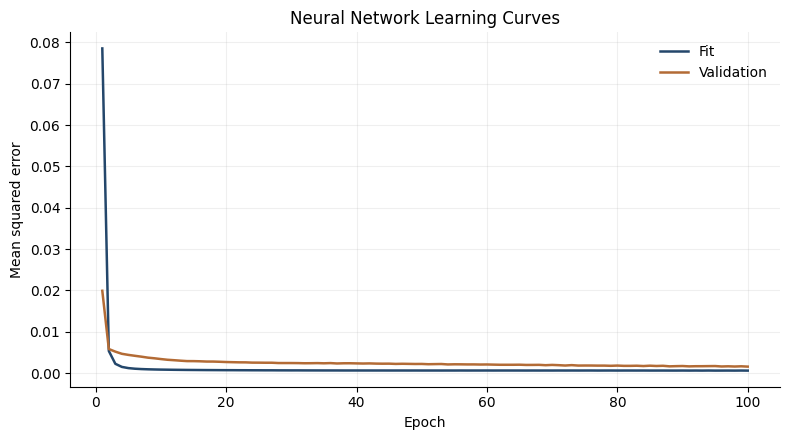

In [27]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    validation_history.index,
    validation_history["Fit MSE"],
    label="Fit",
    color="#24476B",
    linewidth=1.8,
)

ax.plot(
    validation_history.index,
    validation_history["Validation MSE"],
    label="Validation",
    color="#B36B35",
    linewidth=1.8,
)

ax.set_title("Neural Network Learning Curves")
ax.set_xlabel("Epoch")
ax.set_ylabel("Mean squared error")
ax.grid(alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

Fit and validation losses decrease over training. After the first
few epochs, validation loss remains above fit loss.

Keeping the architecture and 100-epoch training schedule fixed, we
retrain the network on the full training sample. The scaler is also
refitted on that sample. The test sample is used only for evaluation.

In [28]:
# Fit preprocessing on the full training sample.
scaler_nn_final = StandardScaler()

X_train_scaled_final = scaler_nn_final.fit_transform(X_train)
X_test_scaled_final = scaler_nn_final.transform(X_test)

# Train a new network with the original architecture and schedule.
keras.utils.set_random_seed(SEED)

nn = build_neural_network()

nn.fit(
    X_train_scaled_final,
    y_train.to_numpy(),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    verbose=0,
)

# Evaluate on training and test samples.
y_pred_train_nn = nn.predict(
    X_train_scaled_final, verbose=0
).ravel()

y_pred_test_nn = nn.predict(
    X_test_scaled_final, verbose=0
).ravel()

nn_results = pd.DataFrame(
    {
        "MSE": [
            mean_squared_error(y_train, y_pred_train_nn),
            mean_squared_error(y_test, y_pred_test_nn),
        ],
        "R²": [
            r2_score(y_train, y_pred_train_nn),
            r2_score(y_test, y_pred_test_nn),
        ],
    },
    index=pd.Index(["Train", "Test"], name="Sample"),
)

display(
    nn_results.style.format({
        "MSE": "{:.6f}",
        "R²": "{:.4f}",
    })
)

,MSE,R²
Sample,,
Train,0.000561,0.9979
Test,0.008819,0.9746


The neural network achieves a test MSE of 0.008819 and an R² of
0.9746, outperforming the Random Forest on this test sample.
Errors remain higher than in training, where MSE is 0.000561.
These results refer to the selected chronological split.

## 8. Black Model Benchmark

We compute Black-model deltas using the futures price, strike,
time to maturity, and 20-day annualized historical volatility.

Following the original specification, we use the undiscounted
delta convention:

$$
d_1 = \frac{\ln(F/K) + \frac{1}{2}\sigma^2\tau}
{\sigma\sqrt{\tau}},
\qquad
\Delta_{\mathrm{call}} = \Phi(d_1),
\qquad
\Delta_{\mathrm{put}} = \Phi(d_1)-1.
$$

Historical volatility is used instead of option-implied volatility.
The dataset's delta convention has not been independently verified,
so convention differences may contribute to estimation errors.

In [29]:
from scipy.stats import norm


def black_delta(data):
    F = data["F"].to_numpy()
    K = data["K"].to_numpy()
    tau = data["tau"].to_numpy()
    sigma = data["sigma"].to_numpy()
    is_call = data["is_call"].to_numpy()

    d1 = (
        np.log(F / K) + 0.5 * sigma**2 * tau
    ) / (sigma * np.sqrt(tau))

    return norm.cdf(d1) - (1 - is_call)


y_pred_train_black = black_delta(train)
y_pred_test_black = black_delta(test)

black_results = pd.DataFrame(
    {
        "MSE": [
            mean_squared_error(y_train, y_pred_train_black),
            mean_squared_error(y_test, y_pred_test_black),
        ],
        "R²": [
            r2_score(y_train, y_pred_train_black),
            r2_score(y_test, y_pred_test_black),
        ],
    },
    index=pd.Index(["Train", "Test"], name="Sample"),
)

display(
    black_results.style.format({
        "MSE": "{:.6f}",
        "R²": "{:.4f}",
    })
)

,MSE,R²
Sample,,
Train,0.002736,0.9898
Test,0.004243,0.9878


The Black benchmark achieves a test MSE of 0.004243 and an R² of
0.9878, outperforming both machine learning models on this test sample.
Despite using historical rather than implied volatility, it provides
the closest approximation to the recorded deltas among the three
models on the test sample.

## 9. Model Comparison and Diagnostics

We compare the three models on the same test observations using MSE
and R². We then examine estimation errors over time, across strikes,
and by option type.

In [30]:
comparison = pd.DataFrame(
    {
        "Random Forest": rf_results.loc["Test"],
        "Neural Network": nn_results.loc["Test"],
        "Black": black_results.loc["Test"],
    }
).T

comparison.index.name = "Model"

display(
    comparison.style.format({
        "MSE": "{:.6f}",
        "R²": "{:.4f}",
    })
)

# Store predictions and errors for the following diagnostics.
test_predictions = test[
    ["date", "K", "type", "delta"]
].copy()

predictions = {
    "Random Forest": y_pred_test_rf,
    "Neural Network": y_pred_test_nn,
    "Black": y_pred_test_black,
}

for model_name, prediction in predictions.items():
    test_predictions[model_name] = prediction
    test_predictions[f"{model_name} error"] = (
        prediction - test_predictions["delta"]
    )

,MSE,R²
Model,,
Random Forest,0.022081,0.9364
Neural Network,0.008819,0.9746
Black,0.004243,0.9878


Black has the lowest test MSE, followed by the neural network and
the Random Forest. This ranking describes performance on the selected
test period and does not establish superiority across other samples.

For the following diagnostics, errors are defined as predicted minus
recorded delta. Positive errors indicate overestimation; negative
errors indicate underestimation.

### 9.1. Estimation Errors over Time

We plot individual test-sample errors over time, using a common
vertical scale across models. Each date contains ten option observations.

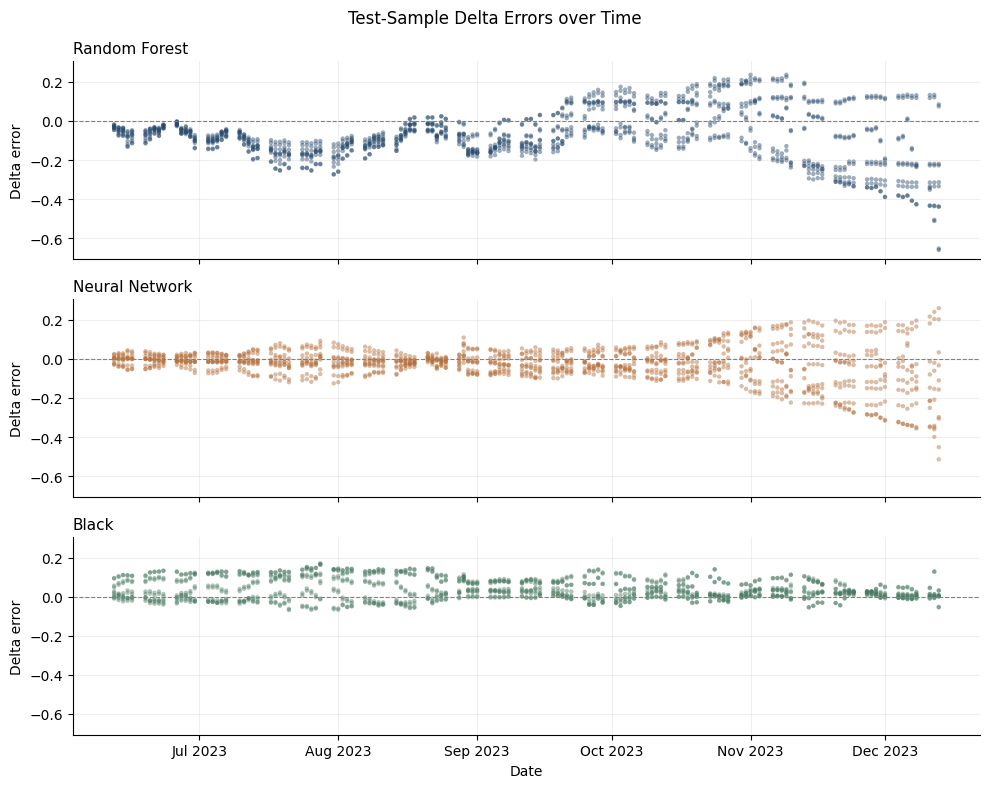

In [31]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

MODEL_COLORS = {
    "Random Forest": "#24476B",
    "Neural Network": "#B36B35",
    "Black": "#497A63",
}

fig, axes = plt.subplots(
    3, 1, figsize=(10, 8), sharex=True, sharey=True
)

for ax, (model_name, color) in zip(axes, MODEL_COLORS.items()):
    ax.scatter(
        test_predictions["date"],
        test_predictions[f"{model_name} error"],
        color=color,
        s=10,
        alpha=0.45,
        edgecolors="none",
    )

    ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")
    ax.set_title(model_name, loc="left", fontsize=11)
    ax.set_ylabel("Delta error")
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axes[-1].set_xlabel("Date")

fig.suptitle("Test-Sample Delta Errors over Time")
plt.tight_layout()
plt.show()

Errors vary over the test period. The Random Forest predominantly
underestimates delta during the early months, while both machine
learning models show a wider spread of errors towards expiration.

Black errors remain more contained but are predominantly positive,
indicating a tendency to overestimate the recorded deltas.
The figure alone does not identify the causes of these patterns.

### 9.2. Estimation Errors by Strike

We compare test-sample error distributions across the five strike
prices. Each boxplot pools call and put observations over the test period.

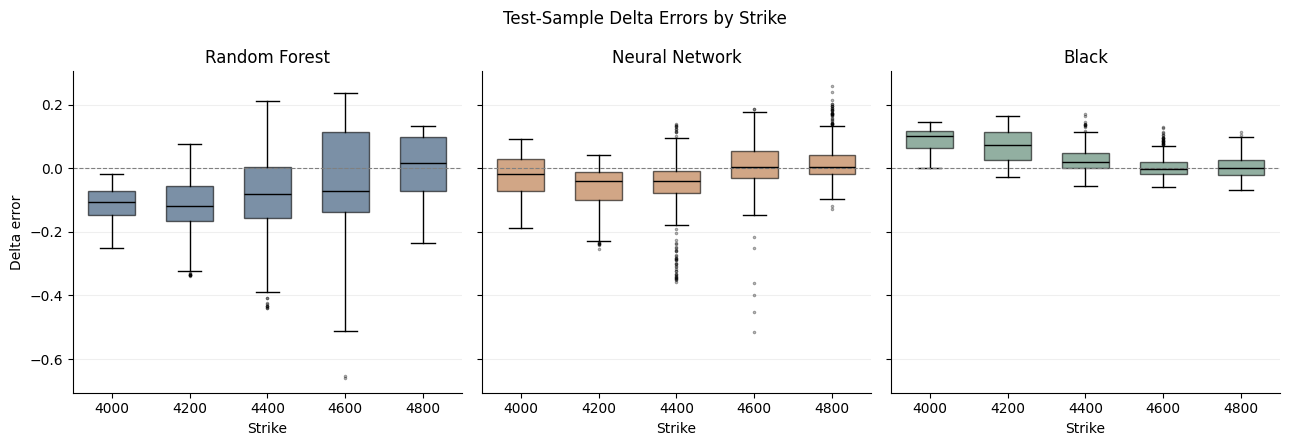

In [32]:
fig, axes = plt.subplots(
    1, 3, figsize=(13, 4.5), sharey=True
)

for ax, (model_name, color) in zip(axes, MODEL_COLORS.items()):
    errors_by_strike = [
        test_predictions.loc[
            test_predictions["K"].eq(strike),
            f"{model_name} error",
        ].to_numpy()
        for strike in STRIKES
    ]

    boxes = ax.boxplot(
        errors_by_strike,
        positions=range(len(STRIKES)),
        widths=0.6,
        patch_artist=True,
        medianprops={"color": "black"},
        flierprops={
            "marker": ".",
            "markersize": 3,
            "alpha": 0.4,
        },
    )

    for box in boxes["boxes"]:
        box.set_facecolor(color)
        box.set_alpha(0.6)

    ax.set_xticks(range(len(STRIKES)))
    ax.set_xticklabels(STRIKES)
    ax.set_title(model_name)
    ax.set_xlabel("Strike")
    ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Delta error")

fig.suptitle("Test-Sample Delta Errors by Strike")
plt.tight_layout()
plt.show()

Error distributions differ across strikes. Random Forest median errors
are negative at strikes 4000–4600 and slightly positive at 4800.
The neural network generally has medians closer to zero, although
substantial negative outliers remain, particularly at 4400 and 4600.

Black shows positive median errors at the lower strikes, with medians
closer to zero at 4600 and 4800. Its lower overall MSE therefore
coexists with systematic differences across strikes.

### 9.3. Estimation Errors by Option Type

We compare test-sample error distributions for calls and puts,
pooling observations across strikes and dates.

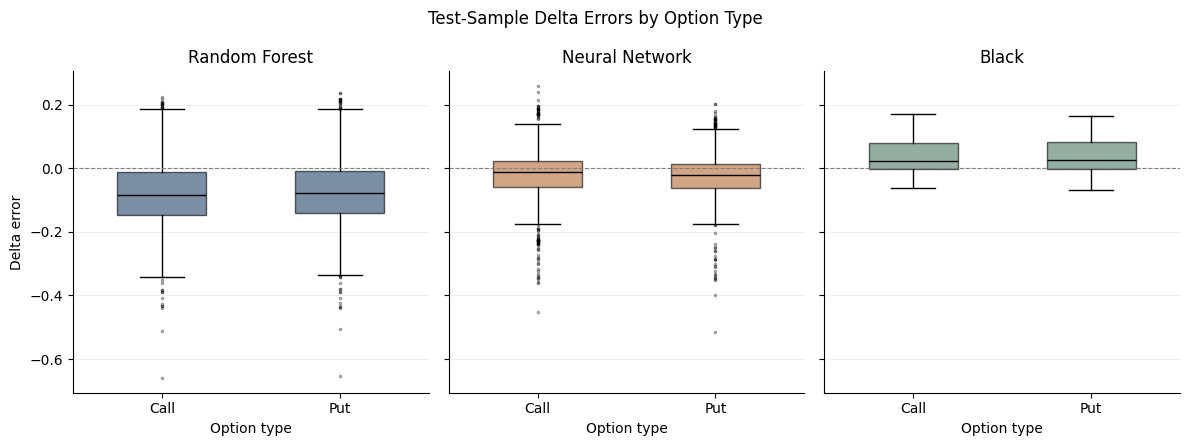

In [33]:
fig, axes = plt.subplots(
    1, 3, figsize=(12, 4.5), sharey=True
)

for ax, (model_name, color) in zip(axes, MODEL_COLORS.items()):
    errors_by_type = [
        test_predictions.loc[
            test_predictions["type"].eq(option_type),
            f"{model_name} error",
        ].to_numpy()
        for option_type in OPTION_TYPES
    ]

    boxes = ax.boxplot(
        errors_by_type,
        positions=[0, 1],
        widths=0.5,
        patch_artist=True,
        medianprops={"color": "black"},
        flierprops={
            "marker": ".",
            "markersize": 3,
            "alpha": 0.4,
        },
    )

    for box in boxes["boxes"]:
        box.set_facecolor(color)
        box.set_alpha(0.6)

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Call", "Put"])
    ax.set_title(model_name)
    ax.set_xlabel("Option type")
    ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Delta error")

fig.suptitle("Test-Sample Delta Errors by Option Type")
plt.tight_layout()
plt.show()

Call and put error distributions are broadly similar within each model.
The Random Forest has negative median errors for both option types.
Neural network medians are closer to zero, although substantial negative
outliers remain. Black has slightly positive median errors and a
narrower error distribution for both calls and puts.

## 10. Discussion and Limitations

On the selected test sample, Black provides the lowest MSE (0.004243),
followed by the neural network (0.008819) and the Random Forest
(0.022081). Error diagnostics reveal differences across dates and
strikes, while call and put error distributions are broadly similar
within each model.

The analysis estimates contemporaneous recorded deltas rather than
forecasting future deltas. It covers five strikes and a single
December 2023 expiration, using one chronological split. Since all
contracts share the same expiration, test observations have shorter
times to maturity than training observations. The comparison therefore
also involves a change in the input distribution.

The Black benchmark uses 20-day historical volatility rather than
option-implied volatility, an approximate weekday-based time to
maturity, and an undiscounted delta convention. The convention and
calculation method underlying the recorded deltas have not been
independently verified. These differences may contribute to the
observed errors.

Results are descriptive: uncertainty in model performance has not
been quantified, and the ranking should not be generalized to other
contracts or market periods. Delta estimation accuracy alone does
not establish hedging effectiveness, which is not evaluated here.